# "Boston Housing" — but using California Housing

I originally meant to use sklearn's `load_boston`, which is the canonical regression starter dataset. It was *removed* in scikit-learn 1.2 because the dataset includes a feature ("B") that encodes a racist assumption about housing prices, and the sklearn maintainers (rightly) decided it shouldn't ship as a built-in example. Their recommended swap is `fetch_california_housing`, so that's what I'm using here.

The folder name is left as `boston_housing` for portfolio-numbering reasons but everything inside is California. Median house value by census block, eight numeric features, ~20k rows.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(0)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

ds = fetch_california_housing(as_frame=True)
df = ds.frame
print(df.shape, df.columns.tolist())
df.head()


(20640, 9) ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## quick look

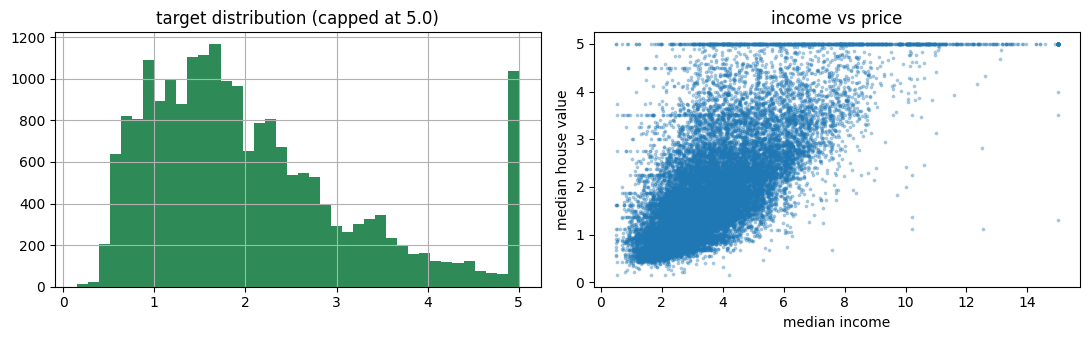

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["MedHouseVal"].hist(bins=40, ax=ax[0], color="seagreen")
ax[0].set_title("target distribution (capped at 5.0)")
ax[1].scatter(df["MedInc"], df["MedHouseVal"], s=3, alpha=0.3)
ax[1].set_xlabel("median income"); ax[1].set_ylabel("median house value")
ax[1].set_title("income vs price")
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()


## models

In [3]:
feature_cols = [c for c in df.columns if c != "MedHouseVal"]
X = df[feature_cols].values
y = df["MedHouseVal"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# scale only matters for the linear ones, but it's harmless to scale once and reuse
sc = StandardScaler().fit(X_train)
Xtr_sc = sc.transform(X_train); Xte_sc = sc.transform(X_test)

results = []
for name, m, scaled in [
    ("LinReg", LinearRegression(), True),
    ("Ridge",  Ridge(alpha=1.0), True),
    ("RF",     RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), False),
    ("GBR",    GradientBoostingRegressor(n_estimators=300, max_depth=3, random_state=0), False),
]:
    Xtr = Xtr_sc if scaled else X_train
    Xte = Xte_sc if scaled else X_test
    m.fit(Xtr, y_train)
    pred = m.predict(Xte)
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    mae = float(mean_absolute_error(y_test, pred))
    r2 = float(r2_score(y_test, pred))
    results.append({"model": name, "rmse": round(rmse, 3), "mae": round(mae, 3), "r2": round(r2, 3)})

pd.DataFrame(results).set_index("model")


,rmse,mae,r2
model,,,
LinReg,0.727,0.535,0.594
Ridge,0.727,0.535,0.594
RF,0.512,0.335,0.799
GBR,0.493,0.337,0.814


## predicted vs actual for the winner

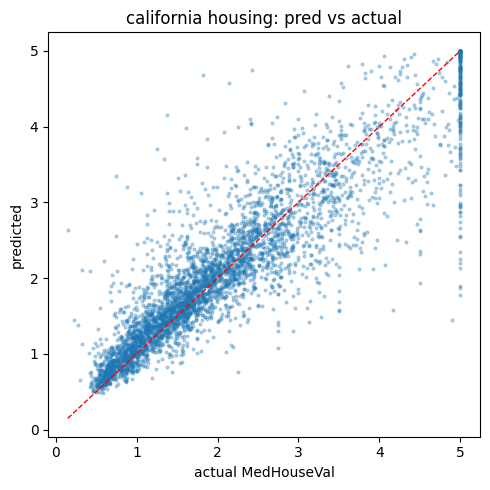

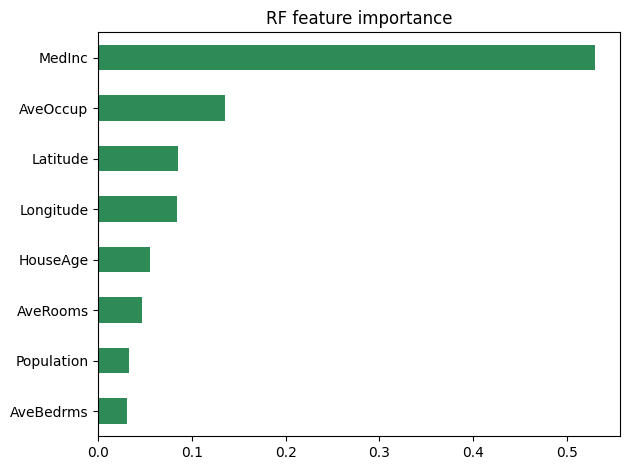

In [4]:
rf = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, pred, s=4, alpha=0.3)
lo, hi = y_test.min(), y_test.max()
ax.plot([lo, hi], [lo, hi], "r--", lw=1)
ax.set_xlabel("actual MedHouseVal"); ax.set_ylabel("predicted")
ax.set_title("california housing: pred vs actual")
plt.tight_layout(); plt.savefig(ART / "pred_vs_actual.png", dpi=120); plt.show()

# importance from RF
fi = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
fi.plot(kind="barh", color="seagreen"); plt.title("RF feature importance")
plt.tight_layout(); plt.savefig(ART / "fi.png", dpi=120); plt.show()


## notes

GBR and RF both clear R^2 around 0.8 without much tuning. MedInc dominates the importance ranking and the scatter plot has a clean upward trend with one annoying horizontal line at the top — that's the dataset's hard cap at 5.0 ($500k), and any model is going to look broken near that ceiling because there's no way to predict beyond it from the features.

If I were taking this further I'd try lat/long-aware features (distance to coast, distance to a major city centroid) — there's an obvious geographic effect the model is currently learning the hard way through `Latitude` / `Longitude` raw.
